<a href="https://colab.research.google.com/github/ammy194/MoodDrive-AI/blob/main/notebooks/02_dataset_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
url = "https://huggingface.co/datasets/premswan/engine-predictive-maintenance-data/resolve/main/engine_data.csv"

df = pd.read_csv(url)

In [ ]:
df.head()

,Engine rpm,Lub oil pressure,Fuel pressure,Coolant pressure,lub oil temp,Coolant temp,Engine Condition
0,700,2.493592,11.790927,3.178981,84.144163,81.632187,1
1,876,2.941606,16.193866,2.464504,77.640934,82.445724,0
2,520,2.961746,6.553147,1.064347,77.752266,79.645777,1
3,473,3.707835,19.510172,3.727455,74.129907,71.774629,1
4,619,5.672919,15.738871,2.052251,78.396989,87.000225,0


In [ ]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Data types
print("\nData Types:")
print(df.dtypes)

# Target distribution
print("\nEngine Condition Distribution:")
print(df["Engine Condition"].value_counts())

Dataset Shape: (19535, 7)

Columns:
['Engine rpm', 'Lub oil pressure', 'Fuel pressure', 'Coolant pressure', 'lub oil temp', 'Coolant temp', 'Engine Condition']

Data Types:
Engine rpm            int64
Lub oil pressure    float64
Fuel pressure       float64
Coolant pressure    float64
lub oil temp        float64
Coolant temp        float64
Engine Condition      int64
dtype: object

Engine Condition Distribution:
Engine Condition
1    12317
0     7218
Name: count, dtype: int64


In [ ]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Rows:")
print(df.duplicated().sum())

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

Missing Values:
Engine rpm          0
Lub oil pressure    0
Fuel pressure       0
Coolant pressure    0
lub oil temp        0
Coolant temp        0
Engine Condition    0
dtype: int64

Duplicate Rows:
0

Statistical Summary:


,Engine rpm,Lub oil pressure,Fuel pressure,Coolant pressure,lub oil temp,Coolant temp,Engine Condition
count,19535.000000,19535.000000,19535.000000,19535.000000,19535.000000,19535.000000,19535.000000
mean,791.239263,3.303775,6.655615,2.335369,77.643420,78.427433,0.630509
std,267.611193,1.021643,2.761021,1.036382,3.110984,6.206749,0.482679
min,61.000000,0.003384,0.003187,0.002483,71.321974,61.673325,0.000000
25%,593.000000,2.518815,4.916886,1.600466,75.725990,73.895421,0.000000
50%,746.000000,3.162035,6.201720,2.166883,76.817350,78.346662,1.000000
75%,934.000000,4.055272,7.744973,2.848840,78.071691,82.915411,1.000000
max,2239.000000,7.265566,21.138326,7.478505,89.580796,195.527912,1.000000


In [ ]:
df.columns.tolist()

['Engine rpm',
 'Lub oil pressure',
 'Fuel pressure',
 'Coolant pressure',
 'lub oil temp',
 'Coolant temp',
 'Engine Condition']

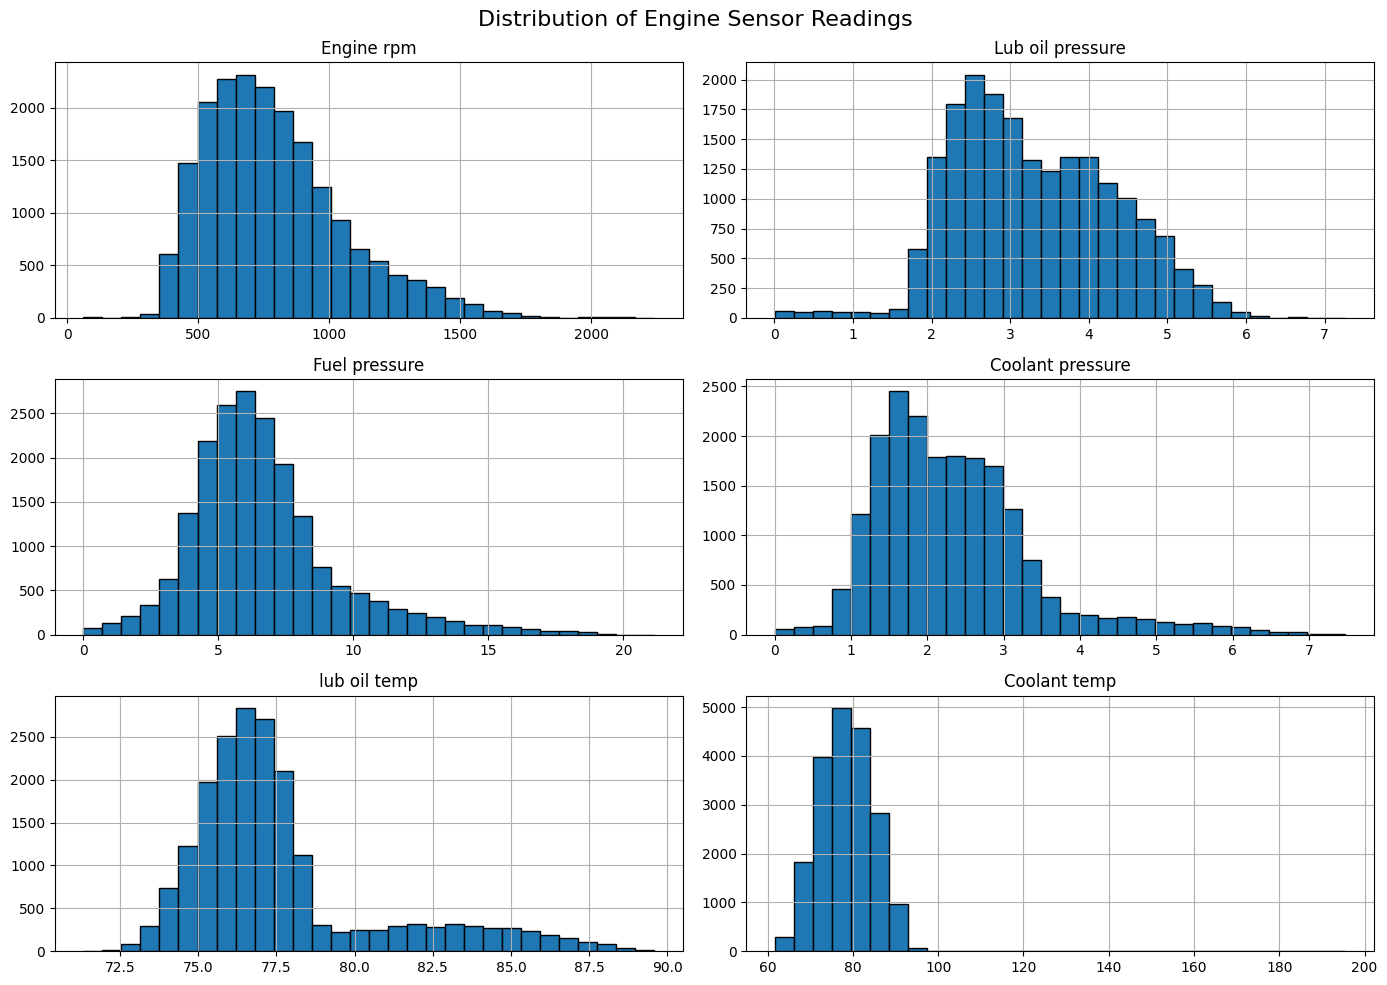

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sensor_columns = [
    'Engine rpm',
    'Lub oil pressure',
    'Fuel pressure',
    'Coolant pressure',
    'lub oil temp',
    'Coolant temp'
]

df[sensor_columns].hist(
    figsize=(14, 10),
    bins=30,
    edgecolor='black'
)

plt.suptitle("Distribution of Engine Sensor Readings", fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
# Sensor Distribution Analysis

##Histograms were plotted for all six sensor features.

###Key observations:

#1. Engine RPM shows a right-skewed distribution.
#2. Lubricating oil pressure shows multiple concentration regions.
#3. Fuel pressure exhibits right skewness.
#4. Coolant pressure is concentrated between 1 and 3.
#5. Lubricating oil temperature shows a potentially bimodal distribution.
#6. Coolant temperature is concentrated between 70 and 90, with possible extreme values requiring investigation.

#These distributions provide an initial understanding of sensor behaviour
#and help identify potential anomalies for further analysis.

In [ ]:
df[sensor_columns].describe()

,Engine rpm,Lub oil pressure,Fuel pressure,Coolant pressure,lub oil temp,Coolant temp
count,19535.000000,19535.000000,19535.000000,19535.000000,19535.000000,19535.000000
mean,791.239263,3.303775,6.655615,2.335369,77.643420,78.427433
std,267.611193,1.021643,2.761021,1.036382,3.110984,6.206749
min,61.000000,0.003384,0.003187,0.002483,71.321974,61.673325
25%,593.000000,2.518815,4.916886,1.600466,75.725990,73.895421
50%,746.000000,3.162035,6.201720,2.166883,76.817350,78.346662
75%,934.000000,4.055272,7.744973,2.848840,78.071691,82.915411
max,2239.000000,7.265566,21.138326,7.478505,89.580796,195.527912


In [ ]:
Q1 = df['Coolant temp'].quantile(0.25)
Q3 = df['Coolant temp'].quantile(0.75)

IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR
lower_bound = Q1 - 1.5 * IQR

print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

outliers = df[df['Coolant temp'] > upper_bound]

print("\nNumber of potential outliers:", len(outliers))
print("\nExtreme readings:")
print(outliers[['Coolant temp']].sort_values(
    by='Coolant temp', ascending=False
).head(10))

IQR: 9.019990405000001
Lower bound: 60.3654353225
Upper bound: 96.4453969425

Number of potential outliers: 2

Extreme readings:
       Coolant temp
2423     195.527912
15123    118.371957


In [ ]:
### Outlier Analysis – Coolant Temperature

#The IQR method was used to identify potential outliers.

#- Q1: 73.8954
#- Q3: 82.9154
#- IQR: 9.0200
#- Upper bound: 96.4454
#- Lower bound: 60.3654

#Two potential outliers were identified:
#1. Row 2423: 195.5279
#2. Row 15123: 118.3719

#These observations will be retained for further investigation.
#No records were removed during exploratory data analysis.

In [ ]:
print(df.dtypes)

Engine rpm            int64
Lub oil pressure    float64
Fuel pressure       float64
Coolant pressure    float64
lub oil temp        float64
Coolant temp        float64
Engine Condition      int64
dtype: object


In [ ]:
timestamp_columns = [
    col for col in df.columns
    if 'time' in col.lower() or 'date' in col.lower()
]

print("Timestamp columns:", timestamp_columns)

Timestamp columns: []


In [ ]:
df.head(10)

,Engine rpm,Lub oil pressure,Fuel pressure,Coolant pressure,lub oil temp,Coolant temp,Engine Condition
0,700,2.493592,11.790927,3.178981,84.144163,81.632187,1
1,876,2.941606,16.193866,2.464504,77.640934,82.445724,0
2,520,2.961746,6.553147,1.064347,77.752266,79.645777,1
3,473,3.707835,19.510172,3.727455,74.129907,71.774629,1
4,619,5.672919,15.738871,2.052251,78.396989,87.000225,0
5,1221,3.989226,6.679231,2.214250,76.401152,75.669818,0
6,716,3.568896,5.312266,2.461067,83.646589,79.792411,1
7,729,3.845166,10.191126,2.362998,77.921202,71.671761,1
8,845,4.877239,3.638269,3.525604,76.301626,70.496024,0
9,824,3.741228,7.626214,1.301032,77.066520,85.143297,0


In [ ]:
df.dtypes

,0
Engine rpm,int64
Lub oil pressure,float64
Fuel pressure,float64
Coolant pressure,float64
lub oil temp,float64
Coolant temp,float64
Engine Condition,int64


In [ ]:
[col for col in df.columns
 if 'time' in col.lower() or 'date' in col.lower()]

[]

In [ ]:
### Timestamp and Sequence Analysis

#The dataset was inspected for temporal and sequential information.

#Findings:

#1. No timestamp or date columns were found.
#2. No explicit engine or machine identifier was found.
#3. The dataset contains six numerical sensor features.
#4. Engine Condition is the target variable.
#5. All observations are currently represented as individual tabular records.

#Conclusion:

#Dataset 1 is suitable for record-level classification.
#However, temporal sequence modelling cannot be established
#using the available columns alone.

#A separate time-series dataset may be required for
#investigating temporal patterns in predictive maintenance.